# Dependence-Robust Sharpe Comparisons

The influence value shows how one return contributes to the sampling error of a Sharpe estimate:

$$
z_t=\frac{r_t-\overline r}{s_r},
\qquad
IF_t=z_t-\frac{1}{2}\widehat{SR}(z_t^2-1).
$$

Here, $r_t$ is return $t$, $\overline r$ and $s_r$ are its sample mean and standard deviation, $z_t$ is the standardized return, $\widehat{SR}$ is the sample Sharpe ratio, and $IF_t$ is the corresponding influence value.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("20_sharpe_multiple_testing");
using CSV, TOML, Printf
prefix = "dependence"
source_path = dataset_path("fred_sp500")
raw = CSV.read(source_path,DataFrame;missingstring=["","."])
dropmissing!(raw,:SP500)
sort!(raw,:observation_date)
price_dates,prices = Date.(raw.observation_date),Float64.(raw.SP500)
returns = vcat(NaN,diff(log.(prices)))

function exponential_average(values,span)
    alpha = 2/(span+1)
    result = copy(values)
    for index in 2:length(values)
        result[index] = (1-alpha)*result[index-1]+alpha*values[index]
    end
    result[1:span-1] .= NaN
    return result
end

columns,catalog_records = Vector{Float64}[],NamedTuple[]
for fast in [3,5,10,20], slow in [30,60,120,240]
    fast_average,slow_average = exponential_average(prices,fast),exponential_average(prices,slow)
    signal = sign.(fast_average.-slow_average)
    for index in 2:length(signal)
        signal[index]==0 && (signal[index]=signal[index-1])
    end
    position = vcat(NaN,signal[1:end-1])
    for (orientation,multiplier) in [("Trend",1.),("Reversal",-1.)]
        name = orientation*" "*string(fast)*"/"*string(slow)
        push!(columns,multiplier.*position.*returns)
        push!(catalog_records,(trial=length(catalog_records)+1,rule=orientation,fast=fast,slow=slow,name=name))
    end
end
complete = findall(vec(all(isfinite,reduce(hcat,columns);dims=2)))
performances = reduce(hcat,columns)[complete,:]
dates = price_dates[complete]
strategy_catalog = DataFrame(catalog_records)
rename!(strategy_catalog,["Trial","Rule","Fast span","Slow span","Name"])
names_trials = strategy_catalog.Name
@assert size(performances)==(2090,32)
performance_frame = DataFrame(performances,names_trials)
insertcols!(performance_frame,1,:date=>dates)
save_data(performance_frame,paths,prefix*"_performances")
save_data(DataFrame(date=price_dates,price=prices),paths,prefix*"_prices")
violet = "#C084FC"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter20-"*replace(name,"_"=>"-"))

using Distributions: Normal,quantile
using RiskLabAI.Backtest: probabilistic_sharpe_ratio,benchmark_sharpe_ratio,lplz_sharpe_inference,newey_west_automatic_lag,newey_west_long_run_variance,sharpe_ratio_influence_function,benjamini_hochberg_yekutieli_adjusted_p_values,haircut_sharpe_ratios,holm_adjusted_p_values,sharpe_ratio_p_values,expected_max_sharpe_ratio,estimated_sharpe_ratio_z_statistics,strategy_type1_error_probability,strategy_type2_error_probability,theta_for_type2_error,sharpe_difference_test

function period_sharpe(values)
    deviation = std(values)
    return deviation>0 ? mean(values)/deviation : 0.
end

function return_moments(values)
    n = length(values)
    centered = values.-mean(values)
    second,third,fourth = mean(centered.^2),mean(centered.^3),mean(centered.^4)
    skewness = sqrt(n*(n-1))/(n-2)*third/second^1.5
    kurtosis = (n-1)/((n-2)*(n-3))*((n+1)*(fourth/second^2-3)+6)+3
    return skewness,kurtosis
end

psr(sharpe,benchmark,n,skewness=0.,kurtosis=3.;return_test_statistic=false) = probabilistic_sharpe_ratio(sharpe,benchmark,n;skewness_of_returns=skewness,kurtosis_of_returns=kurtosis,return_test_statistic)
opposite_name(name) = startswith(name,"Trend") ? replace(name,"Trend"=>"Reversal") : replace(name,"Reversal"=>"Trend")
trial_sharpes = period_sharpe.(eachcol(performances))
annual_sharpes = trial_sharpes.*sqrt(252.)
trial_mean,trial_spread = mean(trial_sharpes),std(trial_sharpes;corrected=false)
observation_count,trial_count = size(performances)

function read_primitive(name)
    root = joinpath("..","data","chapter20_random_inputs")
    manifest_path = joinpath(root,"inputs.toml")
    metadata = TOML.parsefile(manifest_path)["files"][name*".bin"]
    path = joinpath(root,name*".bin")
    values = reinterpret(Float64,ltoh.(reinterpret(UInt64,read(path))))
    @assert length(values)==metadata["values"]
    return reshape(values,Tuple(metadata["shape"]))
end

function ar1_values(innovations,persistence;scale=.01)
    values = zeros(size(innovations))
    for index in 2:size(values,1)
        values[index,:] = persistence.*values[index-1,:].+scale.*innovations[index,:]
    end
    return values
end


ar1_values (generic function with 1 method)

## Single-Sharpe Inference with Serial Dependence

A Bartlett-weighted long-run variance adds sample autocovariances to the ordinary variance:

$$
\widehat\Omega_L=\widehat\gamma_0+2\sum_{\ell=1}^{L}\left(1-\frac{\ell}{L+1}\right)\widehat\gamma_\ell,
\qquad
\widehat{SE}_{HAC}(\widehat{SR})=\sqrt{\frac{\widehat\Omega_L}{T}}.
$$

Here, $\widehat\gamma_\ell$ is the sample autocovariance of the influence values at lag $\ell$, $L$ is the largest included lag, $\widehat\Omega_L$ is the estimated long-run variance, $T$ is the number of returns, and $\widehat{SE}_{HAC}$ is the resulting standard error of the Sharpe estimate.

Row,Trial,Name,Annual Sharpe,Lag-one return correlation,Automatic lag,Independent standard error,HAC standard error,HAC lower limit,HAC upper limit,HAC two-sided p-value
,Int64,String,Float64,Float64,Int64,Float64,Float64,Float64,Float64,Float64
1,1,Trend 3/30,0.368432,-0.161666,7,0.346968,0.295543,-0.210821,0.947686,0.212534
2,2,Reversal 3/30,-0.368432,-0.161666,7,0.346968,0.295543,-0.947686,0.210821,0.212534
3,3,Trend 3/60,0.252547,-0.162639,7,0.347164,0.307401,-0.349947,0.855041,0.41133
4,4,Reversal 3/60,-0.252547,-0.162639,7,0.347164,0.307401,-0.855041,0.349947,0.41133
5,5,Trend 3/120,0.290021,-0.148358,7,0.347426,0.315692,-0.328724,0.908767,0.358261
6,6,Reversal 3/120,-0.290021,-0.148358,7,0.347426,0.315692,-0.908767,0.328724,0.358261
7,7,Trend 3/240,0.19922,-0.144621,7,0.347548,0.314509,-0.417205,0.815646,0.526451
8,8,Reversal 3/240,-0.19922,-0.144621,7,0.347548,0.314509,-0.815646,0.417205,0.526451
9,9,Trend 5/30,0.448622,-0.145134,7,0.346558,0.294945,-0.129459,1.0267,0.12825


Row,Trial,Name,Annual Sharpe,Lag-one return correlation,Automatic lag,Independent standard error,HAC standard error,HAC lower limit,HAC upper limit,HAC two-sided p-value
,Int64,String,Float64,Float64,Int64,Float64,Float64,Float64,Float64,Float64
1,9,Trend 5/30,0.448622,-0.145134,7,0.346558,0.294945,-0.129459,1.0267,0.12825
2,27,Trend 20/60,0.413375,-0.136726,7,0.347326,0.308618,-0.191504,1.01825,0.180427
3,13,Trend 5/120,0.370794,-0.148718,7,0.347533,0.310652,-0.238073,0.97966,0.232635
4,1,Trend 3/30,0.368432,-0.161666,7,0.346968,0.295543,-0.210821,0.947686,0.212534
5,21,Trend 10/120,0.356375,-0.142714,7,0.347313,0.308331,-0.247942,0.960692,0.247755
6,17,Trend 10/30,0.342441,-0.155509,7,0.346688,0.303342,-0.252098,0.936979,0.258943
7,5,Trend 3/120,0.290021,-0.148358,7,0.347426,0.315692,-0.328724,0.908767,0.358261
8,3,Trend 3/60,0.252547,-0.162639,7,0.347164,0.307401,-0.349947,0.855041,0.41133
9,15,Trend 5/240,0.250915,-0.167993,7,0.34745,0.30354,-0.344012,0.845841,0.408447


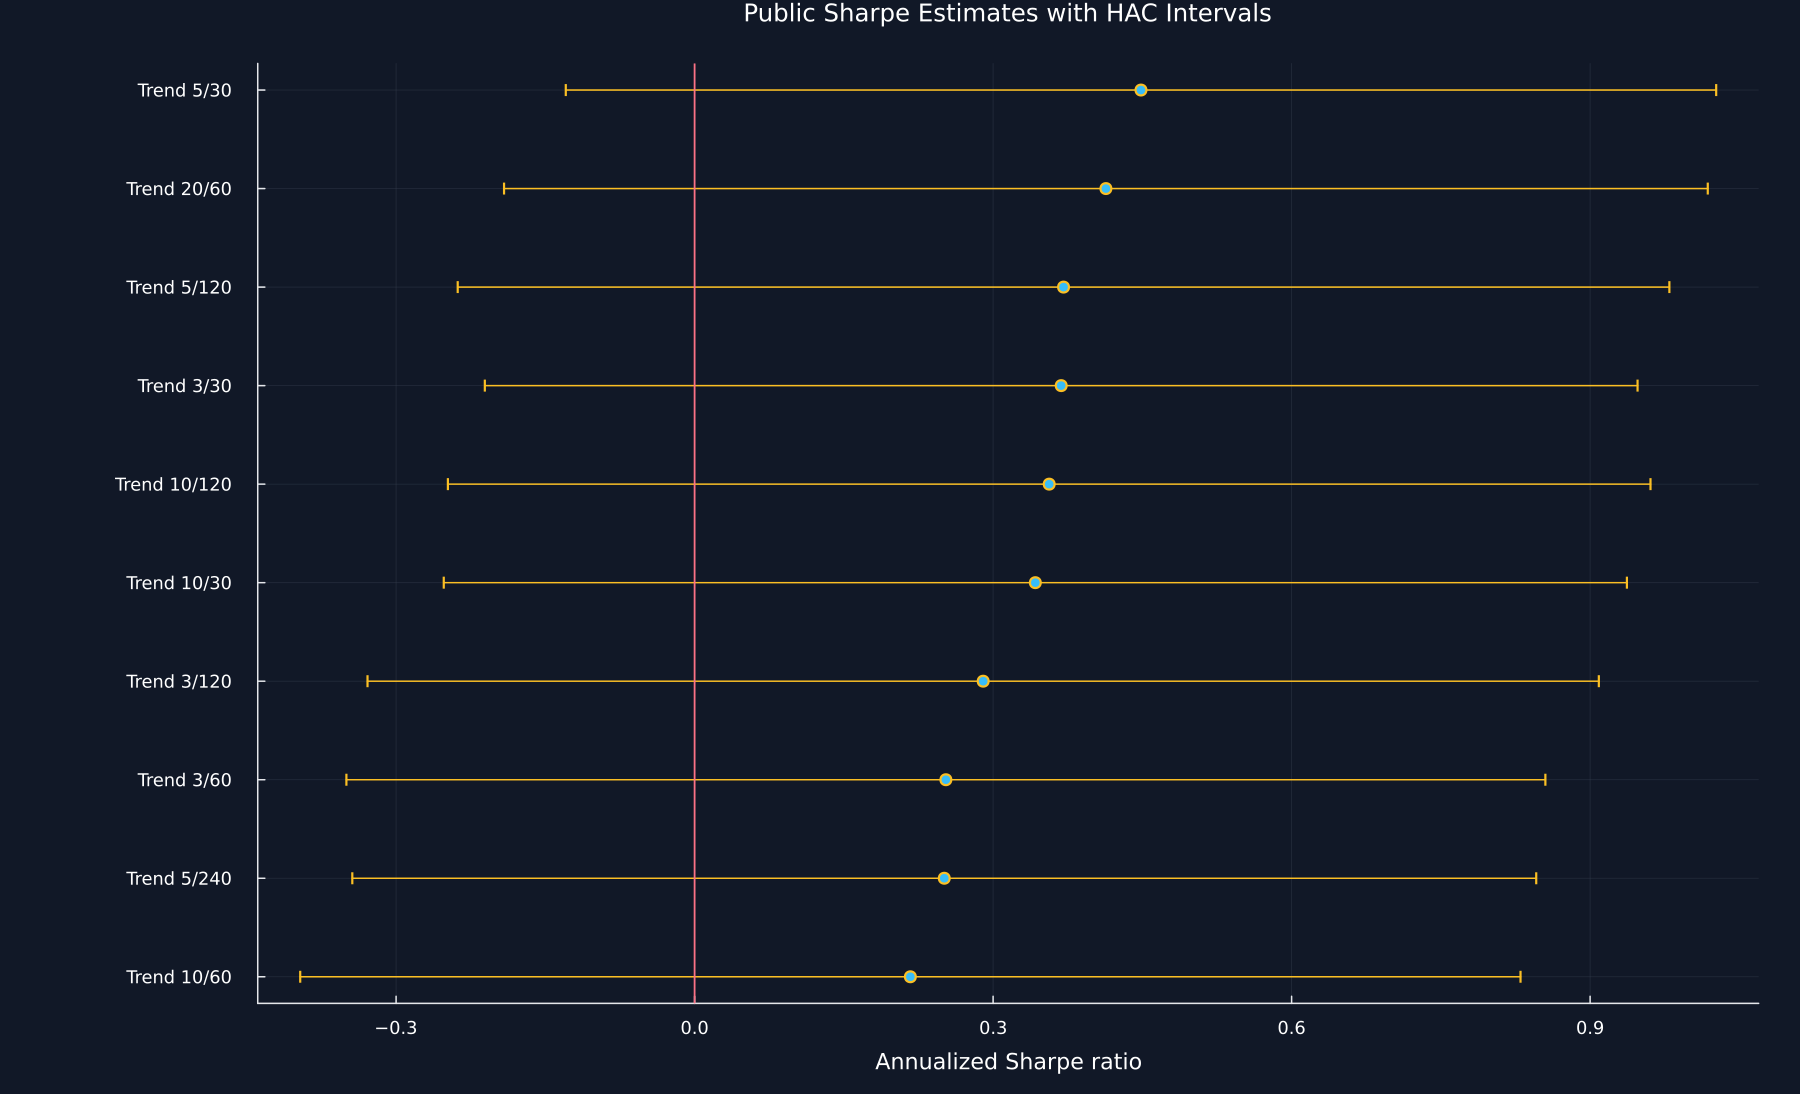

In [2]:
single_rows = NamedTuple[]
for (trial,name) in enumerate(names_trials)
    values = performances[:,trial]
    sharpe = period_sharpe(values)
    skewness,kurtosis = return_moments(values)
    iid_variance = 1-skewness*sharpe+(kurtosis-1)*sharpe^2/4
    iid_error = sqrt(max(iid_variance,0.)/(length(values)-1))
    result = lplz_sharpe_inference(values)
    push!(single_rows,(trial=trial,name=name,sharpe=sharpe*sqrt(252.),lag_one=cor(values[1:end-1],values[2:end]),lag=result.lag,iid_error=iid_error*sqrt(252.),hac_error=result.standard_error*sqrt(252.),lower=result.confidence_interval[1]*sqrt(252.),upper=result.confidence_interval[2]*sqrt(252.),p=result.p_value))
end
single_sharpe_inference = DataFrame(single_rows)
rename!(single_sharpe_inference,["Trial","Name","Annual Sharpe","Lag-one return correlation","Automatic lag","Independent standard error","HAC standard error","HAC lower limit","HAC upper limit","HAC two-sided p-value"])
leading_single_inference = first(sort(single_sharpe_inference,["Annual Sharpe","Trial"];rev=[true,false]),10)
table(single_sharpe_inference,"single_sharpe_inference","Dependence-robust Sharpe inference for every public trial.")
table(leading_single_inference,"leading_single_inference","Dependence-robust intervals for the ten largest public Sharpe estimates.")
ordered = sort(leading_single_inference,"Annual Sharpe")
figure = scatter(ordered[!,"Annual Sharpe"],1:10;xerror=(ordered[!,"Annual Sharpe"].-ordered[!,"HAC lower limit"],ordered[!,"HAC upper limit"].-ordered[!,"Annual Sharpe"]),color=palette.cyan,markerstrokecolor=palette.amber,label="",yticks=(1:10,ordered.Name),xlabel="Annualized Sharpe ratio",title="Public Sharpe Estimates with HAC Intervals",size=(1200,730),left_margin=18Plots.mm)
vline!(figure,[0.];color=palette.rose,label="",linewidth=1.2)
save_figure(figure,paths,"public_hac_intervals")


A paired comparison tests the difference between two Sharpe ratios with a standard error that preserves their joint time order:

$$
\widehat\Delta=\widehat{SR}_A-\widehat{SR}_B,
\qquad
Z_{HAC}=\frac{|\widehat\Delta|}{\widehat{SE}_{HAC}(\widehat\Delta)},
\qquad
\widehat p_{boot}=\frac{1+\sum_{b=1}^{B}\mathbf 1\{|Z_b^*|\geq Z_{HAC}\}}{B+1}.
$$

Here, $\widehat\Delta$ is the observed Sharpe difference, $\widehat{SE}_{HAC}(\widehat\Delta)$ is its long-run standard error, $Z_{HAC}$ is the absolute standardized difference, $B$ is the number of circular-block resamples, $Z_b^*$ is the centered studentized statistic in resample $b$, and $\widehat p_{boot}$ is the two-sided bootstrap p-value.

## Paired Public Comparisons

Row,First trial,Second trial,Annual Sharpe difference,Independent standard error,HAC standard error,Independent p-value,Block-bootstrap p-value,Independent rejection,Block-bootstrap rejection
,String,String,Float64,Float64,Float64,Float64,Float64,Bool,Bool
1,Trend 5/30,Trend 20/60,0.0352547,0.305745,0.267159,0.908202,0.91,false,false
2,Trend 5/30,Reversal 5/30,0.897458,0.692949,0.567513,0.195276,0.115,false,false
3,Trend 10/120,Reversal 10/120,0.71292,0.694459,0.599587,0.304616,0.2175,false,false


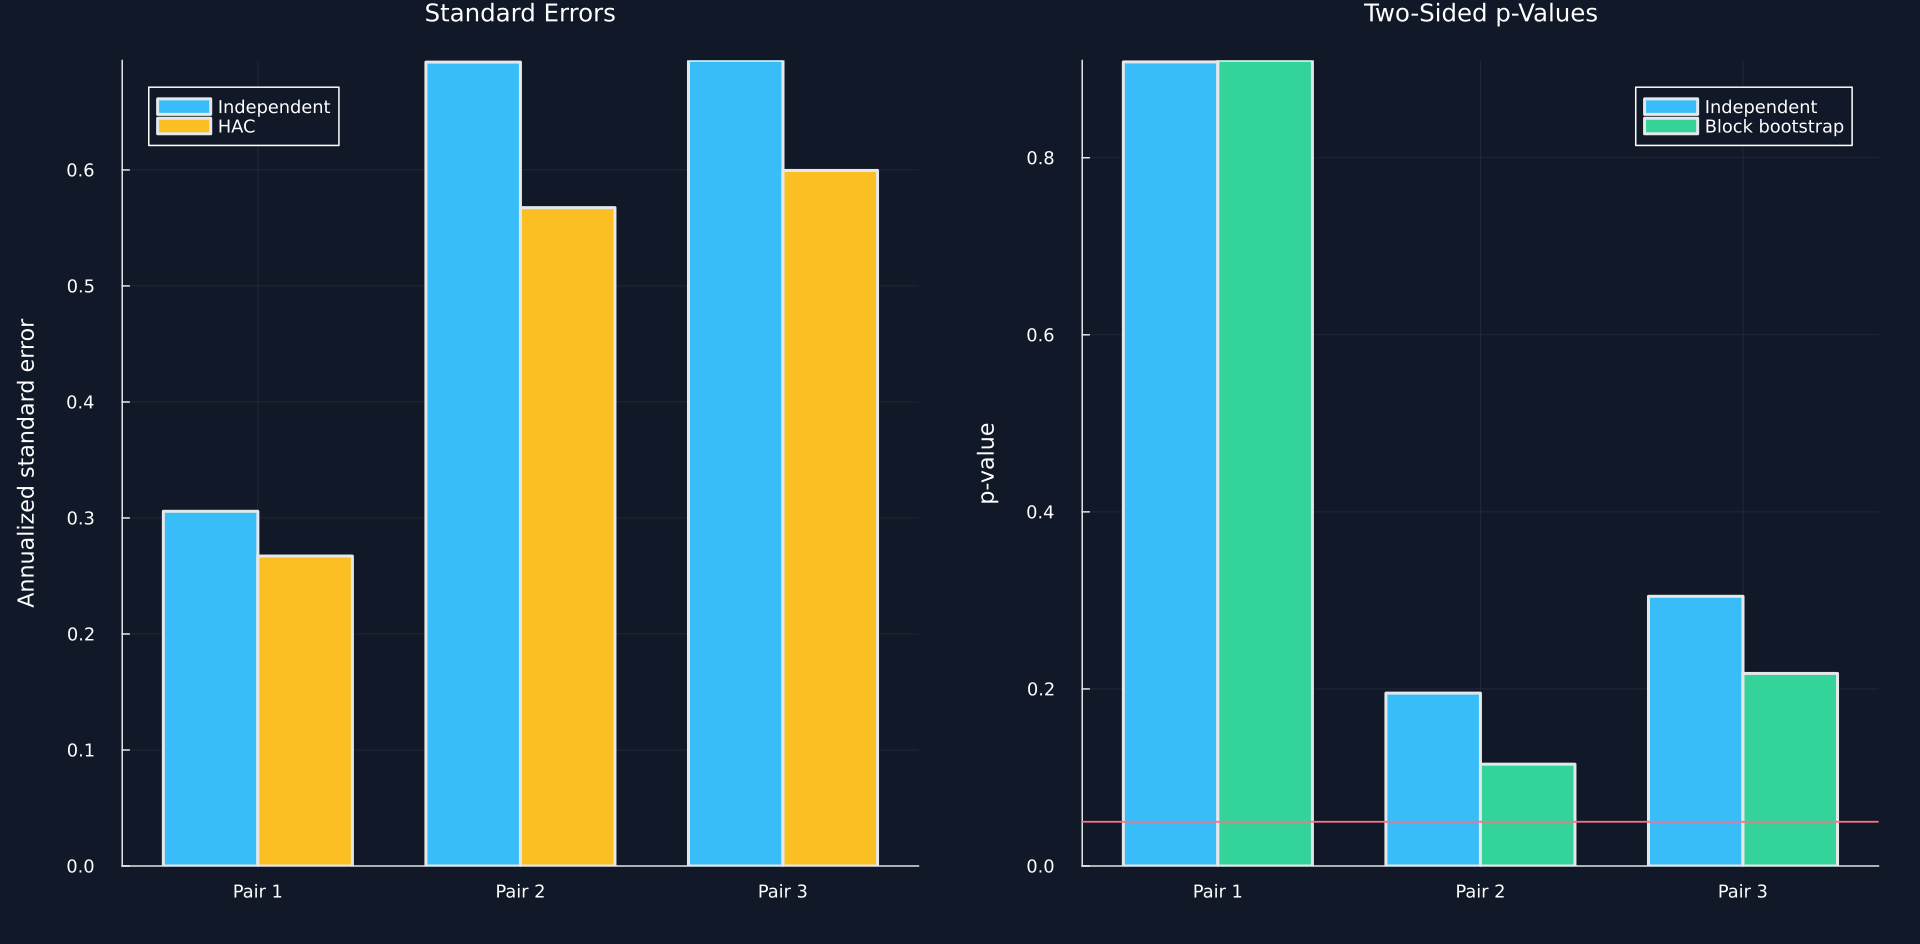

In [3]:
ranked_trials = sortperm(annual_sharpes;rev=true)
first_name,second_name = names_trials[ranked_trials[1]],names_trials[ranked_trials[2]]
pair_names = [(first_name,second_name),(first_name,opposite_name(first_name)),("Trend 10/120","Reversal 10/120")]
pair_rows = NamedTuple[]

function compare_pair(values_a,values_b,key,rows)
    naive = sharpe_difference_test(values_a,values_b;method="naive")
    robust = sharpe_difference_test(values_a,values_b;method="ledoit_wolf",n_boot=length(rows),bootstrap_indices=rows)
    for (method,result) in [("naive",naive),("ledoit_wolf",robust)]
        push!(pair_rows,(case=key,method=method,observations=length(values_a),delta=result.delta,se=result.se,stat=result.stat,pvalue=result.pvalue,reject=result.reject))
    end
    return naive,robust
end

comparison_rows = NamedTuple[]
for (pair,(name_a,name_b)) in enumerate(pair_names)
    a,b = findfirst(==(name_a),names_trials),findfirst(==(name_b),names_trials)
    rows = collect(eachcol(Int.(read_primitive("public_bootstrap_"*string(pair)))))
    naive,robust = compare_pair(performances[:,a],performances[:,b],"public_"*string(pair),rows)
    push!(comparison_rows,(first=name_a,second=name_b,difference=robust.delta*sqrt(252.),iid_error=naive.se*sqrt(252.),hac_error=robust.se*sqrt(252.),iid_p=naive.pvalue,block_p=robust.pvalue,iid_reject=naive.reject,block_reject=robust.reject))
end
public_sharpe_comparisons = DataFrame(comparison_rows)
rename!(public_sharpe_comparisons,["First trial","Second trial","Annual Sharpe difference","Independent standard error","HAC standard error","Independent p-value","Block-bootstrap p-value","Independent rejection","Block-bootstrap rejection"])
table(public_sharpe_comparisons,"public_sharpe_comparisons","Paired public Sharpe comparisons before and after dependence correction.")
save_data(DataFrame(pair_rows),paths,"public_pair_fits")
labels = ["Pair "*string(index) for index in 1:3]
p1 = plot(;title="Standard Errors",ylabel="Annualized standard error",xticks=(1:3,labels),legend=:topleft)
p2 = plot(;title="Two-Sided p-Values",ylabel="p-value",xticks=(1:3,labels),legend=:topright)
bar!(p1,collect(1:3).-.18,public_sharpe_comparisons[!,"Independent standard error"];bar_width=.36,color=palette.cyan,label="Independent")
bar!(p1,collect(1:3).+.18,public_sharpe_comparisons[!,"HAC standard error"];bar_width=.36,color=palette.amber,label="HAC")
bar!(p2,collect(1:3).-.18,public_sharpe_comparisons[!,"Independent p-value"];bar_width=.36,color=palette.cyan,label="Independent")
bar!(p2,collect(1:3).+.18,public_sharpe_comparisons[!,"Block-bootstrap p-value"];bar_width=.36,color=palette.green,label="Block bootstrap")
hline!(p2,[.05];color=palette.rose,label="",linewidth=1.2)
save_figure(plot(p1,p2;layout=(1,2),size=(1280,630),left_margin=7Plots.mm,bottom_margin=7Plots.mm),paths,"public_sharpe_comparison")


A controlled autoregressive return has a known zero mean and a chosen amount of serial dependence:

$$
r_t=\phi r_{t-1}+\varepsilon_t,
\qquad
\varepsilon_t\overset{iid}{\sim}\mathcal N(0,\sigma_\varepsilon^2).
$$

Here, $r_t$ is the return at time $t$, $\phi$ is the persistence parameter, $\varepsilon_t$ is an independent normal shock, $\sigma_\varepsilon$ is its standard deviation, and the true Sharpe ratio is zero because the process has zero unconditional mean.

## Controlled False-Positive Rates

Row,Calculation,Rejections,Simulations,False-positive rate
,String,Int64,Int64,Float64
1,PSR with independent-return variance,46,300,0.153333
2,HAC influence-function inference,8,300,0.0266667


Row,Persistence,Simulations,PSR false-positive rate,HAC false-positive rate
,Float64,Int64,Float64,Float64
1,0.0,200,0.035,0.02
2,0.2,200,0.09,0.04
3,0.4,200,0.15,0.05
4,0.6,200,0.19,0.05


Row,Persistence,Simulations,Independent false-positive rate,Block-bootstrap false-positive rate
,Float64,Int64,Float64,Float64
1,0.0,60,0.0333333,0.05
2,0.4,60,0.2,0.0166667


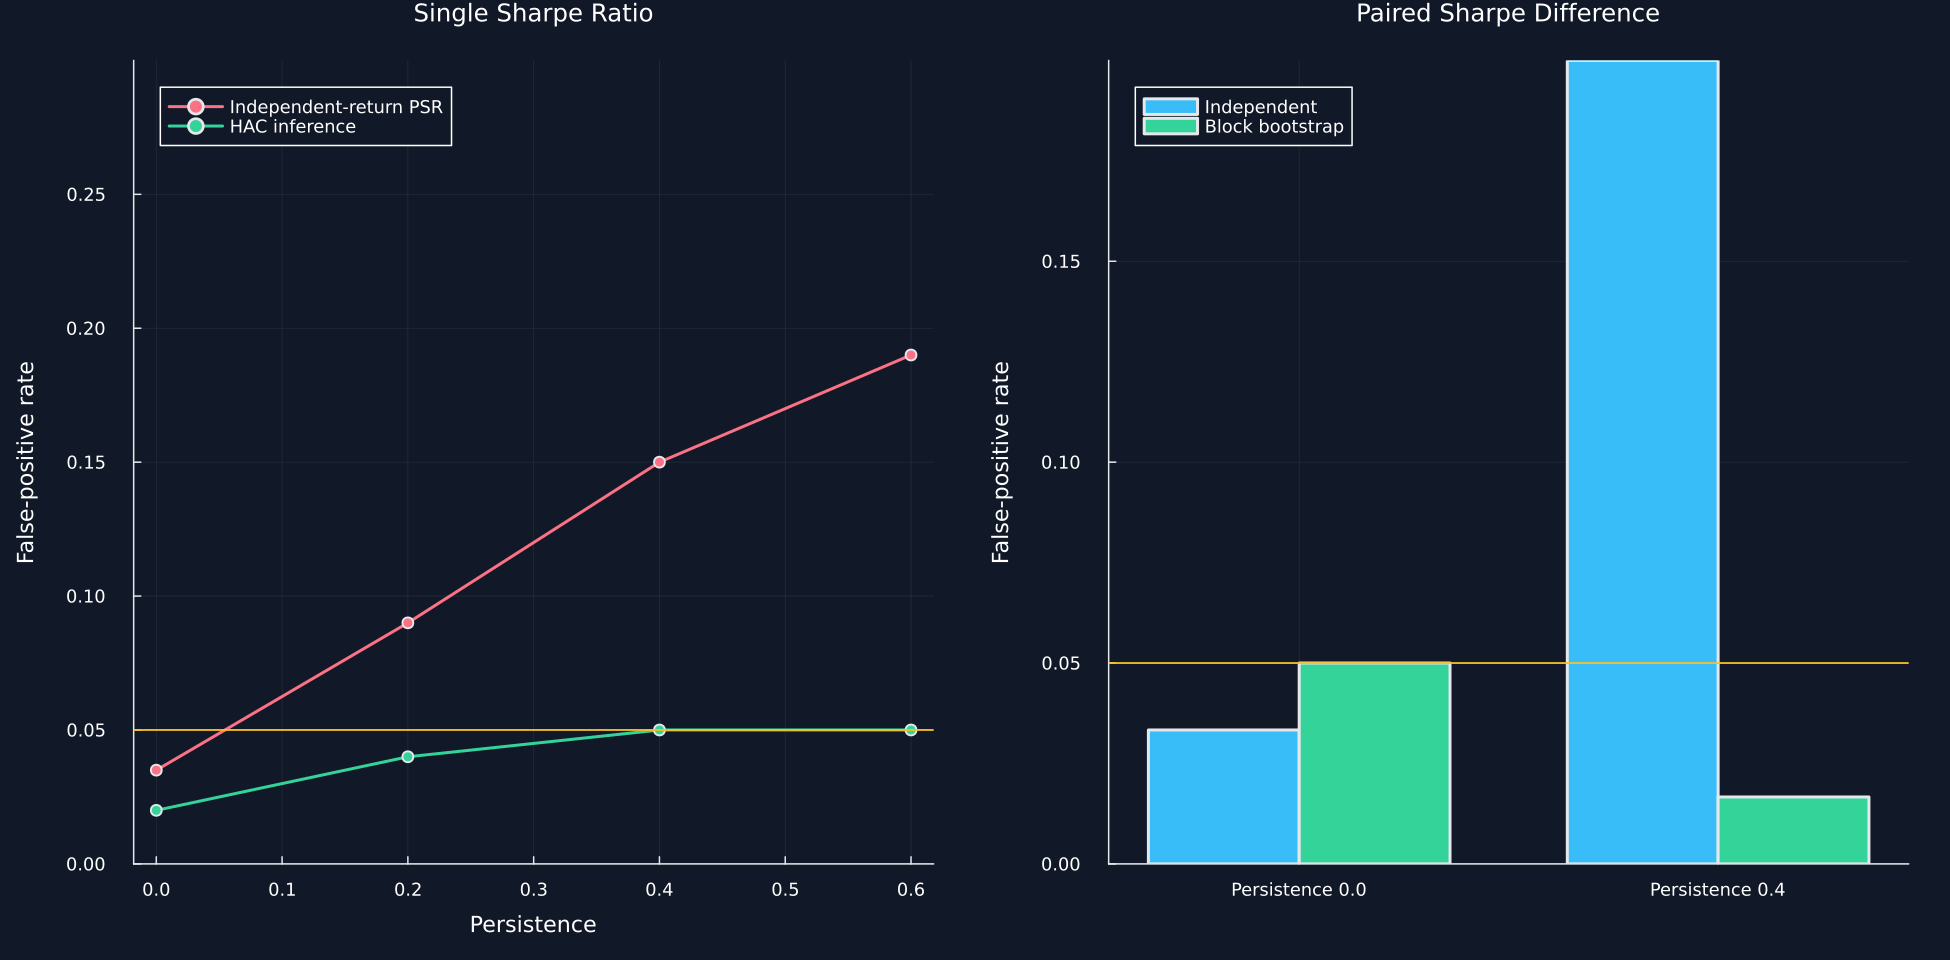

In [4]:
single_null_rows = NamedTuple[]

function evaluate_single(values,key,repetition)
    sharpe = period_sharpe(values)
    skewness,kurtosis = return_moments(values)
    probability = psr(sharpe,0.,length(values),skewness,kurtosis)
    robust = lplz_sharpe_inference(values)
    independent_reject = probability>.95
    robust_reject = robust.p_value<.05 && robust.sharpe_ratio>0
    push!(single_null_rows,(case=key,repetition=repetition,sharpe=sharpe,skewness=skewness,kurtosis=kurtosis,psr=probability,hac_error=robust.standard_error,hac_p=robust.p_value,psr_reject=independent_reject,hac_reject=robust_reject))
    return independent_reject,robust_reject
end

preliminary_counts = Dict("PSR"=>0,"HAC"=>0)
innovations = read_primitive("ar1_preliminary")
for repetition in 1:300
    values = vec(ar1_values(innovations[:,repetition:repetition],.4))
    independent_reject,robust_reject = evaluate_single(values,"preliminary",repetition)
    preliminary_counts["PSR"] += independent_reject
    preliminary_counts["HAC"] += robust_reject
end
preliminary_ar1_reproduction = DataFrame("Calculation"=>["PSR with independent-return variance","HAC influence-function inference"],"Rejections"=>[preliminary_counts["PSR"],preliminary_counts["HAC"]],"Simulations"=>[300,300],"False-positive rate"=>[preliminary_counts["PSR"]/300,preliminary_counts["HAC"]/300])
false_positive_rows = NamedTuple[]
for persistence in [0.,.2,.4,.6]
    code = round(Int,1000*persistence)
    innovations = read_primitive("ar1_"*string(code))
    counts = zeros(Int,2)
    for repetition in 1:200
        values = vec(ar1_values(innovations[:,repetition:repetition],persistence))
        independent_reject,robust_reject = evaluate_single(values,"persistence_"*string(code),repetition)
        counts .+= [independent_reject,robust_reject]
    end
    push!(false_positive_rows,(persistence=persistence,simulations=200,psr=counts[1]/200,hac=counts[2]/200))
end
ar1_false_positive_summary = DataFrame(false_positive_rows)
rename!(ar1_false_positive_summary,["Persistence","Simulations","PSR false-positive rate","HAC false-positive rate"])
paired_rows = NamedTuple[]
for persistence in [0.,.4]
    code = round(Int,1000*persistence)
    innovations = read_primitive("paired_"*string(code))
    counts = zeros(Int,2)
    for repetition in 1:60
        pairs = ar1_values(innovations[:,:,repetition],persistence)
        rows = collect(eachcol(Int.(read_primitive("paired_bootstrap_"*string(repetition)))))
        naive,robust = compare_pair(pairs[:,1],pairs[:,2],"paired_"*string(code)*"_"*string(repetition),rows)
        counts .+= [naive.reject,robust.reject]
    end
    push!(paired_rows,(persistence=persistence,simulations=60,iid=counts[1]/60,block=counts[2]/60))
end
paired_null_summary = DataFrame(paired_rows)
rename!(paired_null_summary,["Persistence","Simulations","Independent false-positive rate","Block-bootstrap false-positive rate"])
table(preliminary_ar1_reproduction,"preliminary_ar1_reproduction","Reproduction of the preliminary autoregressive null experiment.")
table(ar1_false_positive_summary,"ar1_false_positive_summary","False-positive rates for single-Sharpe inference as persistence changes.")
table(paired_null_summary,"paired_null_summary","False-positive rates for paired Sharpe comparisons under a known null.")
save_data(DataFrame(single_null_rows),paths,"single_null_inference")
save_data(DataFrame(pair_rows),paths,"all_pair_fits")
p1 = plot(;title="Single Sharpe Ratio",xlabel="Persistence",ylabel="False-positive rate",ylims=(0,max(.3,maximum(Matrix(select(ar1_false_positive_summary,["PSR false-positive rate","HAC false-positive rate"])))+.03)),legend=:topleft)
plot!(p1,ar1_false_positive_summary.Persistence,ar1_false_positive_summary[!,"PSR false-positive rate"];color=palette.rose,marker=:circle,label="Independent-return PSR")
plot!(p1,ar1_false_positive_summary.Persistence,ar1_false_positive_summary[!,"HAC false-positive rate"];color=palette.green,marker=:circle,label="HAC inference")
hline!(p1,[.05];color=palette.amber,label="",linewidth=1.2)
p2 = plot(;title="Paired Sharpe Difference",ylabel="False-positive rate",xticks=([1,2],["Persistence 0.0","Persistence 0.4"]),legend=:topleft)
bar!(p2,[1,2].-.18,paired_null_summary[!,"Independent false-positive rate"];bar_width=.36,color=palette.cyan,label="Independent")
bar!(p2,[1,2].+.18,paired_null_summary[!,"Block-bootstrap false-positive rate"];bar_width=.36,color=palette.green,label="Block bootstrap")
hline!(p2,[.05];color=palette.amber,label="",linewidth=1.2)
save_figure(plot(p1,p2;layout=(1,2),size=(1300,640),left_margin=7Plots.mm,bottom_margin=7Plots.mm),paths,"dependence_false_positive_rates")


## Tests

In [5]:
@assert observation_count==2090
@assert trial_count==32
@assert size(single_sharpe_inference)==(32,10)
@assert size(leading_single_inference)==(10,10)
@assert all(==(newey_west_automatic_lag(observation_count)),single_sharpe_inference[!,"Automatic lag"])
@assert all(>(0),single_sharpe_inference[!,"HAC standard error"])
@assert all(value->0<=value<=1,single_sharpe_inference[!,"HAC two-sided p-value"])
@assert size(public_sharpe_comparisons)==(3,9)
@assert all(value->0<=value<=1,public_sharpe_comparisons[!,"Independent p-value"])
@assert all(value->0<=value<=1,public_sharpe_comparisons[!,"Block-bootstrap p-value"])
@assert preliminary_counts==Dict("PSR"=>46,"HAC"=>8)
@assert preliminary_ar1_reproduction[!,"False-positive rate"]≈[46/300,8/300]
@assert size(ar1_false_positive_summary)==(4,4)
@assert all(value->0<=value<=1,Matrix(select(ar1_false_positive_summary,["PSR false-positive rate","HAC false-positive rate"])))
@assert size(paired_null_summary)==(2,4)
@assert all(value->0<=value<=1,Matrix(select(paired_null_summary,["Independent false-positive rate","Block-bootstrap false-positive rate"])))
sample_values = vec(ar1_values(read_primitive("ar1_assertion"),.4))
influence = sharpe_ratio_influence_function(sample_values)
@assert size(influence)==size(sample_values)
@assert abs(mean(influence))<.01
@assert newey_west_long_run_variance(influence,newey_west_automatic_lag(length(influence)))>0
save_data(DataFrame(returns=sample_values,influence=influence),paths,"assertion_influence");
@assert isfile(joinpath(paths.figures,"public_hac_intervals.pdf"))
@assert isfile(joinpath(paths.figures,"public_sharpe_comparison.pdf"))
@assert isfile(joinpath(paths.figures,"dependence_false_positive_rates.pdf"))
@assert isfile(joinpath(paths.tables,"single_sharpe_inference.tex"))
@assert isfile(joinpath(paths.tables,"leading_single_inference.tex"))
@assert isfile(joinpath(paths.tables,"public_sharpe_comparisons.tex"))
@assert isfile(joinpath(paths.tables,"preliminary_ar1_reproduction.tex"))
@assert isfile(joinpath(paths.tables,"ar1_false_positive_summary.tex"))
@assert isfile(joinpath(paths.tables,"paired_null_summary.tex"))
